# Actividad 1 - Mejora de imagen con poca luz
Imagen: `images/225.png` (The Dark Face). Operaciones punto a punto: ajuste de intensidad, ecualización de histograma y operadores aritméticos.

Cada técnica se define **una sola vez** como función sobre un canal (matriz 2D, uint8) y se aplica de dos formas:
- **RGB por canal**: sobre R, G y B por separado (puede desplazar los colores).
- **Luminancia**: sobre el canal V de HSV, manteniendo H y S (preserva el color).

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def to_gray(im):
    return im if im.ndim == 2 else cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)

def entropy(im):
    """Entropía de Shannon (bits) del histograma de la luminancia."""
    p = np.bincount(to_gray(im).ravel(), minlength=256) / im.shape[0] / im.shape[1]
    p = p[p > 0]
    return -(p * np.log2(p)).sum()

def show(imgs, titles, hist=True):
    """Muestra cada imagen (gris o RGB) con el histograma de su luminancia debajo."""
    n = len(imgs)
    fig, ax = plt.subplots(2 if hist else 1, n, figsize=(5 * n, 7 if hist else 4), squeeze=False)
    for i, (im, t) in enumerate(zip(imgs, titles)):
        ax[0, i].imshow(im, cmap="gray", vmin=0, vmax=255)
        ax[0, i].set_title(t); ax[0, i].axis("off")
        if hist:
            ax[1, i].hist(to_gray(im).ravel(), bins=256, range=(0, 255))
            ax[1, i].set_xlabel("Intensidad"); ax[1, i].set_ylabel("Píxeles")
    plt.tight_layout(); plt.show()

## 1. Carga de la imagen

Tamaño: (720, 1080, 3) | tipo: uint8
Luminancia -> media: 21.5 | desv.: 26.2 | entropía: 5.68 bits


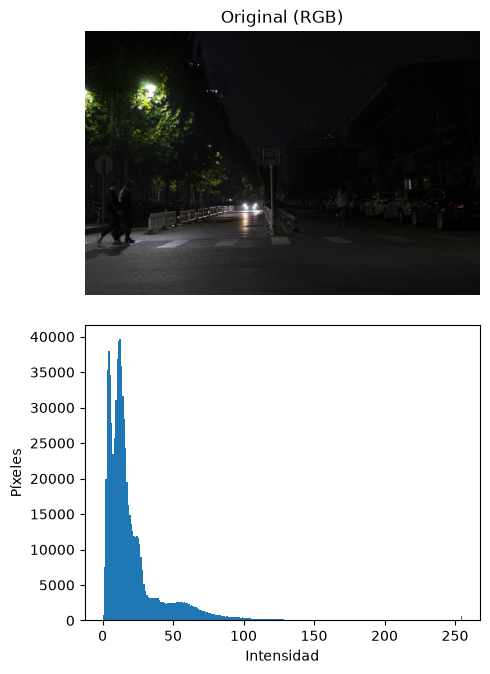

In [2]:
def cargar(ruta):
    return cv2.cvtColor(cv2.imread(ruta), cv2.COLOR_BGR2RGB)

img_rgb = cargar("images/225.png")
lum0 = to_gray(img_rgb)   # luminancia de la original (solo para métricas e histogramas)

print("Tamaño:", img_rgb.shape, "| tipo:", img_rgb.dtype)
print(f"Luminancia -> media: {lum0.mean():.1f} | desv.: {lum0.std():.1f} | entropía: {entropy(lum0):.2f} bits")
show([img_rgb], ["Original (RGB)"])

## 2. Técnicas (funciones sobre un canal uint8)
- **Logarítmica**: `s = c·log(1 + r)`, con `c = 255/log(256)` fija (así todos los canales usan la misma curva).
- **Gamma**: `s = 255·(r/255)^γ`. Con γ < 1 aclara los tonos oscuros.
- **Ecualización** del histograma.
- **Suma** de una constante y **multiplicación** por una ganancia (saturan en 255).

In [3]:
GAMMA = 0.5
SUMA = 60
GANANCIA = 3.0

def t_log(ch):   return (255 / np.log(256) * np.log(1 + ch.astype(np.float64))).astype(np.uint8)
def t_gamma(ch): return (255 * (ch / 255.0) ** GAMMA).astype(np.uint8)
def t_eq(ch):    return cv2.equalizeHist(ch)
def t_suma(ch):  return cv2.add(ch, SUMA)
def t_mult(ch):  return cv2.multiply(ch, GANANCIA)

TECNICAS = {
    "Logarítmica": t_log,
    f"Gamma {GAMMA}": t_gamma,
    "Ecualización": t_eq,
    f"Suma +{SUMA}": t_suma,
    f"Mult x{GANANCIA:g}": t_mult,
}

## 3. Dos formas de aplicarlas

In [4]:
def aplicar_rgb(f, img):
    return cv2.merge([f(img[:, :, c]) for c in range(3)])

def aplicar_lum(f, img):
    h, s, v = cv2.split(cv2.cvtColor(img, cv2.COLOR_RGB2HSV))
    return cv2.cvtColor(cv2.merge([h, s, f(v)]), cv2.COLOR_HSV2RGB)

VARIANTES = {"RGB por canal": aplicar_rgb, "Luminancia (V)": aplicar_lum}

def aplicar_todas(img):
    return {(v, t): fv(ft, img) for v, fv in VARIANTES.items() for t, ft in TECNICAS.items()}

resultados = aplicar_todas(img_rgb)

## 4. Resultados visuales (una fila por técnica: Original | RGB por canal | Luminancia)

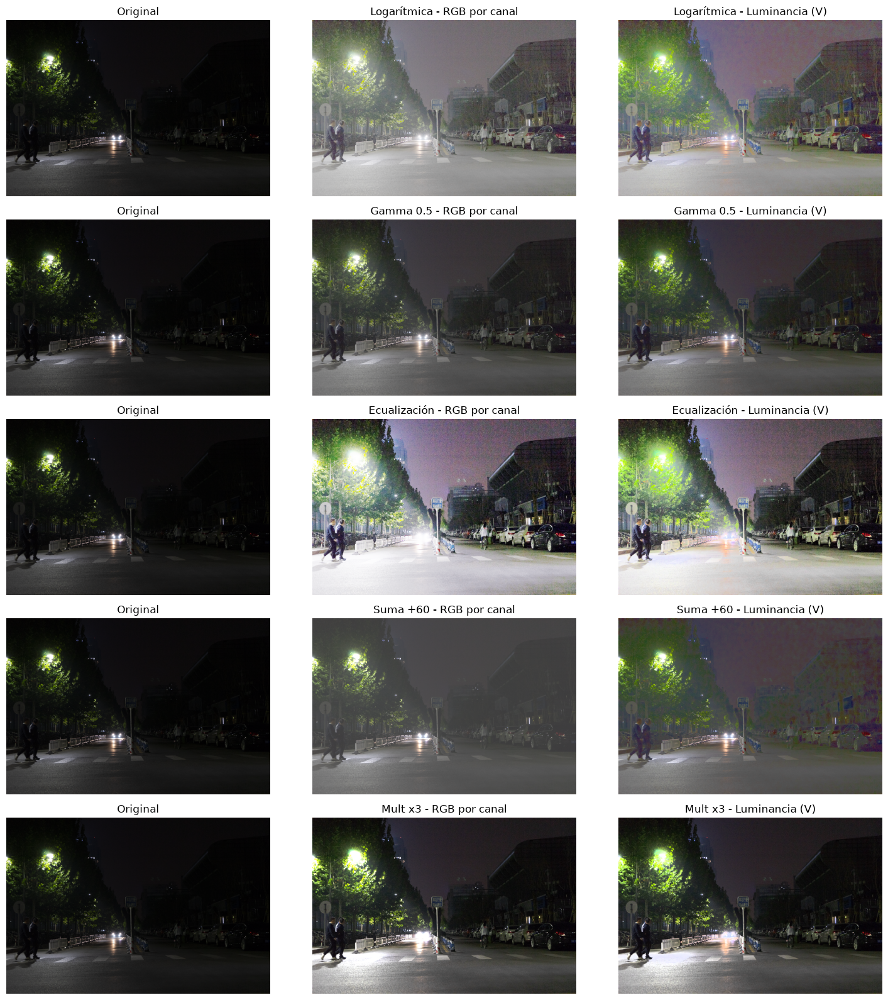

In [5]:
def mostrar_grid(img, res):
    fig, ax = plt.subplots(len(TECNICAS), 3, figsize=(15, 3.2 * len(TECNICAS)))
    for i, t in enumerate(TECNICAS):
        ax[i, 0].imshow(img); ax[i, 0].set_title("Original"); ax[i, 0].axis("off")
        for j, v in enumerate(VARIANTES, start=1):
            ax[i, j].imshow(res[(v, t)], vmin=0, vmax=255)
            ax[i, j].set_title(f"{t} - {v}"); ax[i, j].axis("off")
    plt.tight_layout(); plt.show()

mostrar_grid(img_rgb, resultados)

## 5. Métricas globales
Todas se calculan sobre la imagen completa (luminancia salvo indicación) y las relativas se expresan respecto a la original.
- **Media / Desv. / Entropía**: brillo, contraste global y dispersión del histograma.
- **P1-P99**: rango entre los percentiles 1 y 99 (contraste robusto a extremos).
- **%255 / %0**: porcentaje de valores saturados (por canal); mide pérdida de información.
- **σ ruido**: estimación global de Immerkaer (filtro Laplaciano; no requiere elegir una zona).
- **Amp. ruido**: σ ruido tras / σ ruido antes.
- **SNR global (dB)**: 20·log10(desv. / σ ruido). Aproximación: la desviación incluye estructura y ruido.
- **Δ tono (°)**: cambio medio de tono en Lab (solo píxeles con croma > 5 en ambas imágenes).

In [6]:
KERNEL_NOISE = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], dtype=np.float64)

def sigma_ruido(im):
    """Estimación de Immerkaer de la desviación típica del ruido (luminancia)."""
    g = to_gray(im).astype(np.float64)
    h, w = g.shape
    conv = cv2.filter2D(g, -1, KERNEL_NOISE)[1:-1, 1:-1]   # sin bordes
    return np.sqrt(np.pi / 2) / (6 * (w - 2) * (h - 2)) * np.abs(conv).sum()

def lab(im):
    return cv2.cvtColor(im.astype(np.float32) / 255, cv2.COLOR_RGB2Lab)

def cambio_tono(orig, im):
    """Diferencia angular media (grados) del tono en Lab, en píxeles con croma > 5 en ambas."""
    a0, b0 = lab(orig)[..., 1], lab(orig)[..., 2]
    a1, b1 = lab(im)[..., 1], lab(im)[..., 2]
    mask = (np.hypot(a0, b0) > 5) & (np.hypot(a1, b1) > 5)
    d = np.abs(np.degrees(np.arctan2(b1, a1) - np.arctan2(b0, a0))[mask])
    d = np.minimum(d, 360 - d)
    return d.mean() if mask.any() else np.nan

def metricas(im):
    g = to_gray(im)
    p1, p99 = np.percentile(g, [1, 99])
    sr = sigma_ruido(im)
    return {"media": g.mean(), "desv": g.std(), "entropia": entropy(g), "rango": p99 - p1,
            "p255": 100 * (im == 255).mean(), "p0": 100 * (im == 0).mean(),
            "sigma": sr, "snr": 20 * np.log10(g.std() / sr)}

def tabla_metricas(img, res):
    m0 = metricas(img)
    print(f"{'Técnica':<14}{'Variante':<16}{'Media':>7}{'Desv.':>7}{'Entr.':>7}{'P1-P99':>8}{'%255':>7}{'%0':>7}{'σ ruido':>9}{'Amp.':>7}{'SNR dB':>8}{'Δtono°':>8}")
    print(f"{'Original':<14}{'-':<16}{m0['media']:>7.1f}{m0['desv']:>7.1f}{m0['entropia']:>7.2f}{m0['rango']:>8.0f}{m0['p255']:>7.2f}{m0['p0']:>7.2f}{m0['sigma']:>9.2f}{1:>7.2f}{m0['snr']:>8.1f}{0:>8.1f}")
    for (v, t), im in res.items():
        m = metricas(im)
        print(f"{t:<14}{v:<16}{m['media']:>7.1f}{m['desv']:>7.1f}{m['entropia']:>7.2f}{m['rango']:>8.0f}{m['p255']:>7.2f}{m['p0']:>7.2f}{m['sigma']:>9.2f}{m['sigma'] / m0['sigma']:>7.2f}{m['snr']:>8.1f}{cambio_tono(img, im):>8.1f}")

tabla_metricas(img_rgb, resultados)

Técnica       Variante          Media  Desv.  Entr.  P1-P99   %255     %0  σ ruido   Amp.  SNR dB  Δtono°
Original      -                  21.5   26.2   5.68     130   0.08   0.10     1.38   1.00    25.6     0.0


Logarítmica   RGB por canal     123.9   39.5   7.11     184   0.08   0.10     4.02   2.91    19.8     3.1
Gamma 0.5     RGB por canal      65.2   33.7   6.70     163   0.08   0.10     2.58   1.87    22.3     2.1


Ecualización  RGB por canal     131.2   71.4   7.76     247   0.20   0.10     7.16   5.19    20.0     6.1
Suma +60      RGB por canal      81.3   25.0   5.67     130   0.38   0.00     1.37   0.99    25.2     1.4


Mult x3       RGB por canal      60.4   58.9   6.96     251   2.70   0.10     3.62   2.62    24.2     2.8
Logarítmica   Luminancia (V)    118.7   39.2   7.06     174   0.08   0.10     4.47   3.24    18.9     1.3


Gamma 0.5     Luminancia (V)     63.0   33.4   6.68     158   0.08   0.10     2.74   1.98    21.7     1.3
Ecualización  Luminancia (V)    122.9   70.1   7.69     241   0.12   0.12     6.82   4.94    20.2     1.3


Suma +60      Luminancia (V)     76.7   26.2   6.02     142   0.22   0.08     2.58   1.87    20.1     1.3
Mult x3       Luminancia (V)     59.7   57.5   6.97     241   1.18   0.10     3.62   2.62    24.0     1.3


## 6. Histogramas: original y ecualización en las dos variantes

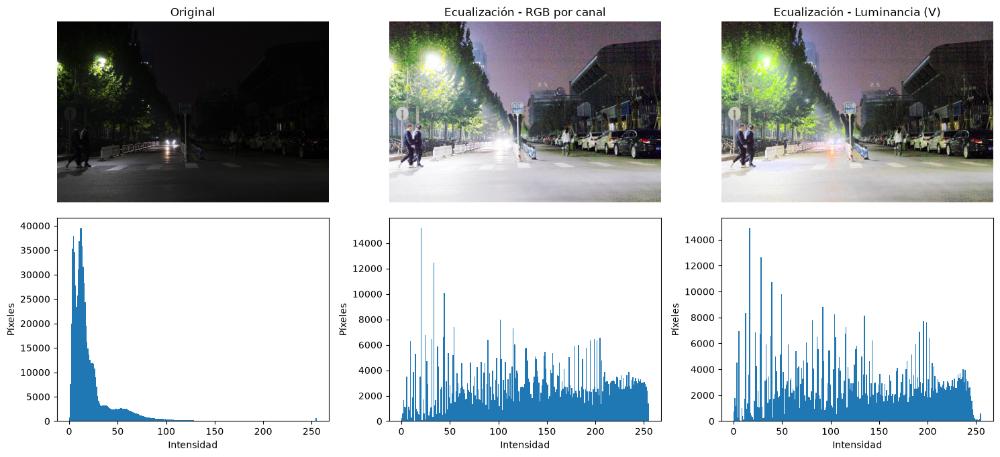

In [7]:
show([img_rgb] + [resultados[(v, "Ecualización")] for v in VARIANTES],
     ["Original"] + [f"Ecualización - {v}" for v in VARIANTES])

## 7. Resto de imágenes
### Imagen 530

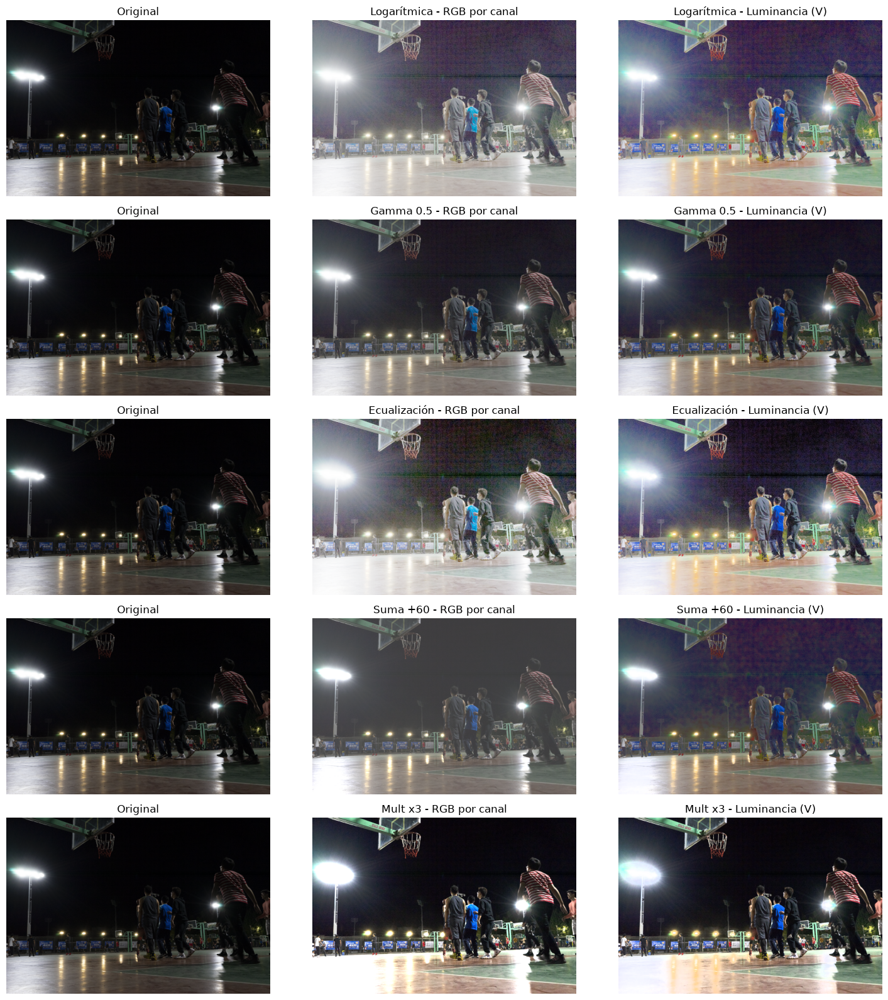

In [8]:
img_530 = cargar("images/530.png")
res_530 = aplicar_todas(img_530)
mostrar_grid(img_530, res_530)

In [9]:
tabla_metricas(img_530, res_530)

Técnica       Variante          Media  Desv.  Entr.  P1-P99   %255     %0  σ ruido   Amp.  SNR dB  Δtono°
Original      -                  36.4   49.9   6.31     223   0.23   0.23     1.34   1.00    31.4     0.0
Logarítmica   RGB por canal     130.8   57.6   7.49     214   0.23   0.23     4.75   3.54    21.7     7.1


Gamma 0.5     RGB por canal      78.3   55.0   7.25     222   0.23   0.23     2.72   2.03    26.1     3.1
Ecualización  RGB por canal     130.6   70.4   7.66     244   0.23   0.27     6.44   4.80    20.8    11.4


Suma +60      RGB por canal      95.6   47.0   6.15     194   3.23   0.00     1.31   0.98    31.1     1.7
Mult x3       RGB por canal      85.5   86.9   6.93     251  11.69   0.23     3.36   2.50    28.3     3.0


Logarítmica   Luminancia (V)    119.2   58.0   7.45     218   0.23   0.23     5.06   3.77    21.2     1.1
Gamma 0.5     Luminancia (V)     73.4   55.0   7.27     225   0.23   0.23     2.91   2.17    25.5     1.3


Ecualización  Luminancia (V)    113.6   70.4   7.65     245   0.23   0.30     6.00   4.47    21.4     1.1
Suma +60      Luminancia (V)     84.5   51.3   7.00     224   1.45   0.18     3.15   2.35    24.2     1.3


Mult x3       Luminancia (V)     83.7   84.3   7.29     249   4.85   0.23     3.38   2.52    27.9     1.2


### Imagen 5678

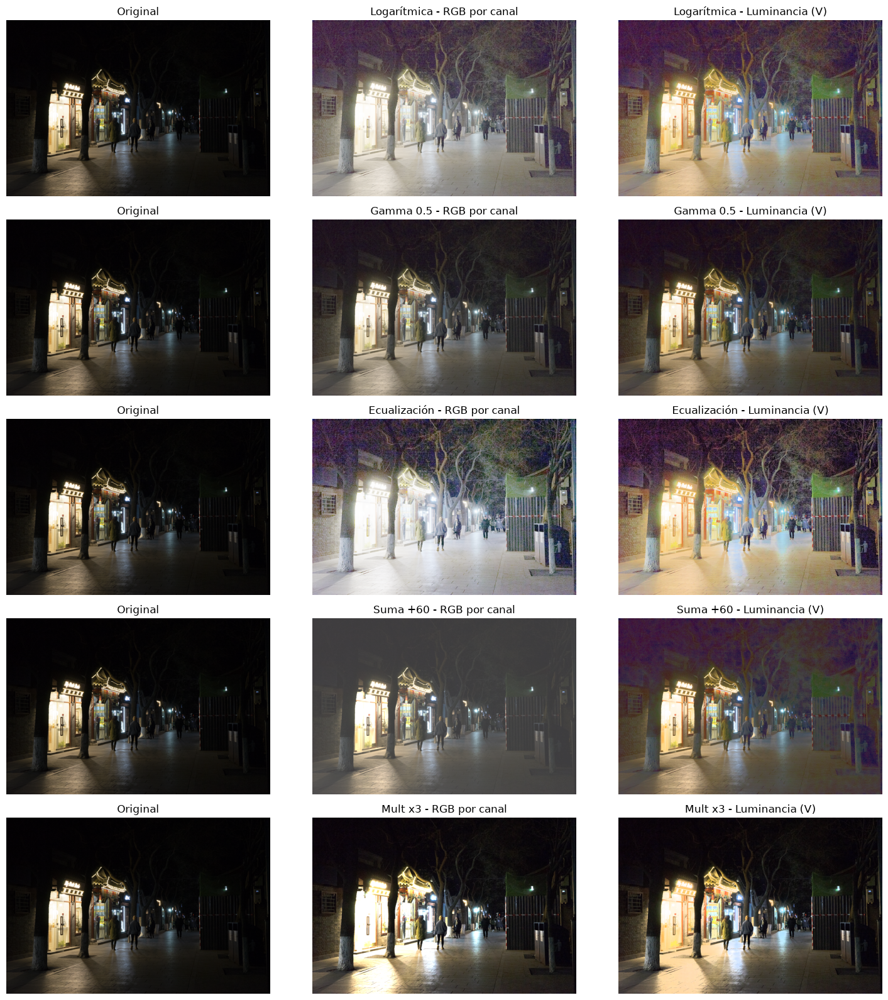

In [ ]:
img_5678 = cargar("images/5678.png")
res_5678 = aplicar_todas(img_5678)
mostrar_grid(img_5678, res_5678)

In [11]:
tabla_metricas(img_5678, res_5678)

Técnica       Variante          Media  Desv.  Entr.  P1-P99   %255     %0  σ ruido   Amp.  SNR dB  Δtono°
Original      -                  28.2   46.9   5.81     243   0.26   0.38     1.50   1.00    29.9     0.0
Logarítmica   RGB por canal     116.0   56.5   7.42     221   0.26   0.38     5.96   3.96    19.5     7.7


Gamma 0.5     RGB por canal      66.3   52.0   7.01     233   0.26   0.38     3.26   2.17    24.0     4.0
Ecualización  RGB por canal     131.9   69.3   7.45     241   0.26   0.38     9.29   6.18    17.5    13.9


Suma +60      RGB por canal      87.2   42.6   5.71     194   2.48   0.00     1.47   0.98    29.2     3.2
Mult x3       RGB por canal      65.2   79.2   6.67     252   9.12   0.38     3.45   2.30    27.2     7.2


Logarítmica   Luminancia (V)    107.1   53.3   7.24     220   0.26   0.38     6.10   4.06    18.8     1.1
Gamma 0.5     Luminancia (V)     62.3   50.2   6.91     233   0.26   0.38     3.38   2.25    23.4     1.2


Ecualización  Luminancia (V)    116.3   66.2   7.46     241   0.26   0.46     9.25   6.16    17.1     1.0
Suma +60      Luminancia (V)     77.4   44.3   6.69     221   1.25   0.35     3.67   2.44    21.6     1.2


Mult x3       Luminancia (V)     62.5   73.6   6.90     246   3.85   0.38     3.41   2.27    26.7     1.2


### Imagen 5803

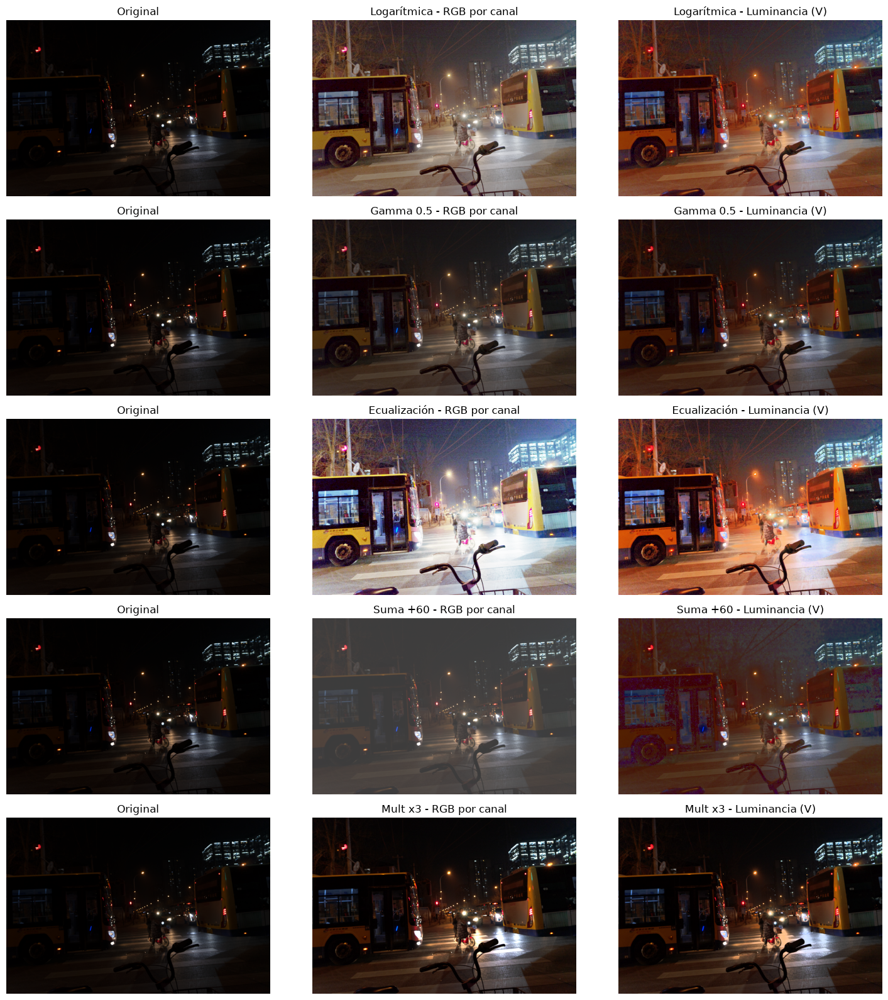

In [12]:
img_5803 = cargar("images/5803.png")
res_5803 = aplicar_todas(img_5803)
mostrar_grid(img_5803, res_5803)

In [13]:
tabla_metricas(img_5803, res_5803)

Técnica       Variante          Media  Desv.  Entr.  P1-P99   %255     %0  σ ruido   Amp.  SNR dB  Δtono°
Original      -                  11.2   20.0   4.81      97   0.06   5.22     0.58   1.00    30.7     0.0
Logarítmica   RGB por canal      86.1   46.5   6.86     201   0.06   5.22     3.53   6.09    22.4    18.4


Gamma 0.5     RGB por canal      42.5   30.5   6.30     152   0.06   5.22     1.73   2.98    24.9    10.1
Ecualización  RGB por canal     128.3   70.5   7.04     244   0.19   5.22     5.81  10.02    21.7    30.2


Suma +60      RGB por canal      71.1   18.8   4.80      97   0.29   0.00     0.58   1.01    30.2     5.0
Mult x3       RGB por canal      31.3   43.2   6.15     253   1.41   5.22     1.48   2.55    29.3     4.1


Logarítmica   Luminancia (V)     72.9   40.5   6.66     179   0.06   5.22     3.70   6.39    20.8     2.3
Gamma 0.5     Luminancia (V)     37.1   28.4   6.05     141   0.06   5.22     1.86   3.21    23.7     2.3


Ecualización  Luminancia (V)     95.7   58.3   6.98     221   0.10   5.22     4.82   8.32    21.7     2.4
Suma +60      Luminancia (V)     53.1   23.6   5.86     130   0.17   4.53     3.84   6.63    15.8     2.4


Mult x3       Luminancia (V)     30.6   41.0   6.13     221   0.69   5.22     1.49   2.57    28.8     2.3
